# ЛР 5. Небинарное дерево на Mushroom
Положительный класс: poisonous=1. Выбраны случайные floor(sqrt(22))=4 признака.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd() / p for p in ['.', 'lab_5', 'module_2/lab_5', 'Artificial_Intelligence_Systems/module_2/lab_5']]
folder = next((p for p in candidates if (p / 'lab5_tree.py').is_file()), None)
if folder is None:
    raise RuntimeError('Откройте папку комплекта или папку лабораторной')
sys.path.insert(0, str(folder.resolve()))
import pandas as pd
from IPython.display import Image, display
from lab5_tree import ROOT, FEATURES, run
df = pd.read_csv(ROOT / 'data/agaricus-lepiota.data', header=None, names=['class'] + FEATURES)
display(df.head())
display(df['class'].value_counts())
print('Пропуски ?: ', int(df.eq('?').sum().sum()))

,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


class
e    4208
p    3916
Name: count, dtype: int64

Пропуски ?:  2480


In [2]:
summary, experiment = run()
display(summary)
print('Признаки:', experiment['selected_features'])
print('Структура:', experiment['tree'])
display(pd.read_csv(ROOT / 'results/validation.csv'))

Случайные признаки: ['stalk_shape', 'cap_surface', 'stalk_color_above_ring', 'veil_type'] ; константные: ['veil_type']
Выбор глубины по validation: {'max_depth': 4, 'accuracy': 0.812923076923077, 'precision': 0.7788125727590222, 'recall': 0.8544061302681992, 'f1': 0.8148599269183922}
Структура: {'nodes': 30, 'leaves': 21, 'depth': 3, 'max_children': 9}
split  accuracy  precision  recall     f1  roc_auc  pr_auc_trapezoid
train    0.8057     0.7667  0.8580 0.8098   0.8991            0.9013
 test    0.8098     0.7724  0.8582 0.8131   0.8967            0.8967


,split,accuracy,precision,recall,f1,roc_auc,pr_auc_trapezoid
0,train,0.805662,0.766686,0.857964,0.809761,0.899141,0.901344
1,test,0.809846,0.772414,0.858238,0.813067,0.896731,0.896686


Признаки: ['stalk_shape', 'cap_surface', 'stalk_color_above_ring', 'veil_type']
Структура: {'nodes': 30, 'leaves': 21, 'depth': 3, 'max_children': 9}


,max_depth,accuracy,precision,recall,f1
0,1,0.734769,0.802405,0.596424,0.684249
1,2,0.747692,0.720189,0.779055,0.748466
2,4,0.812923,0.778813,0.854406,0.814860


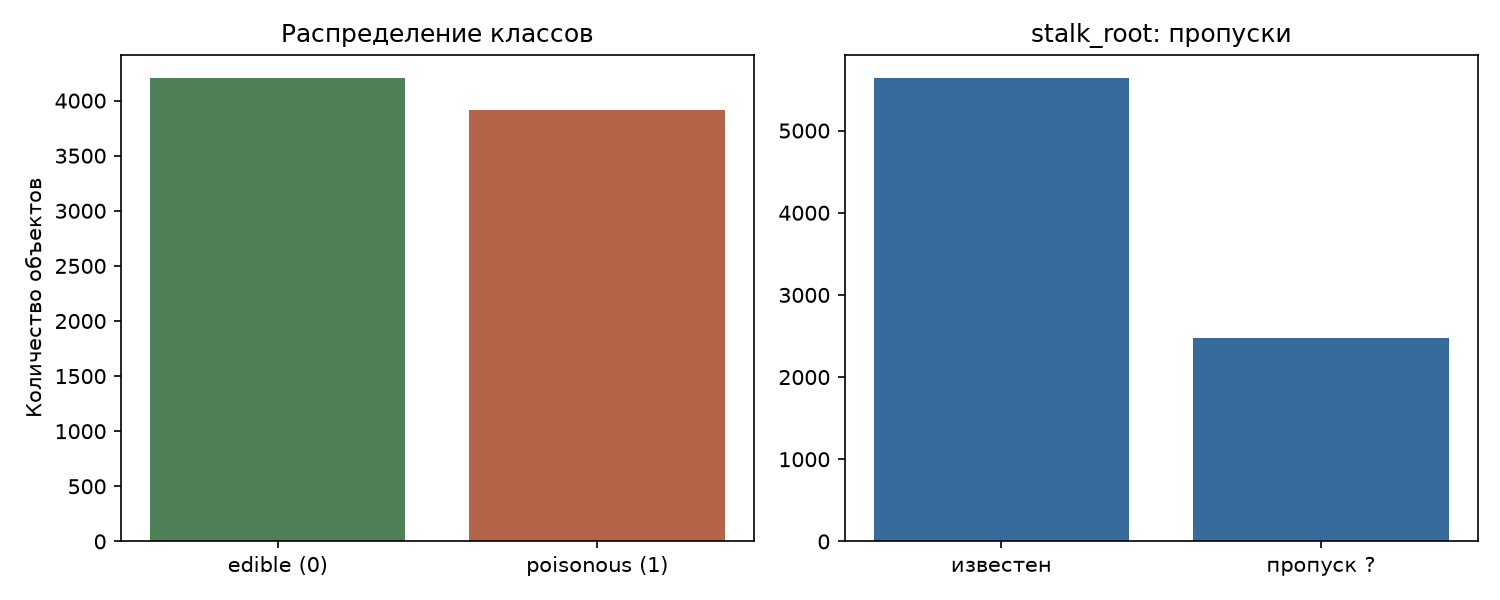

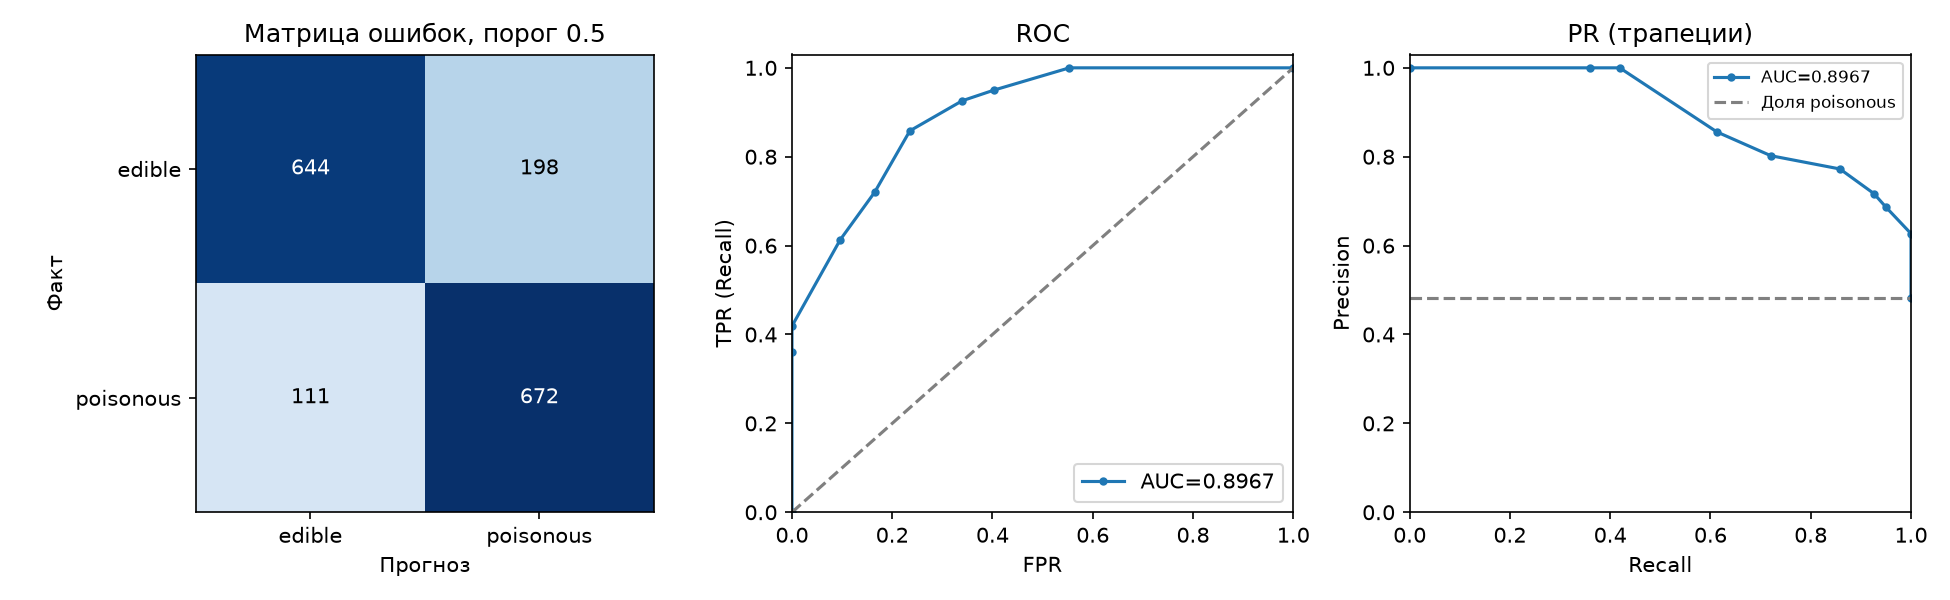

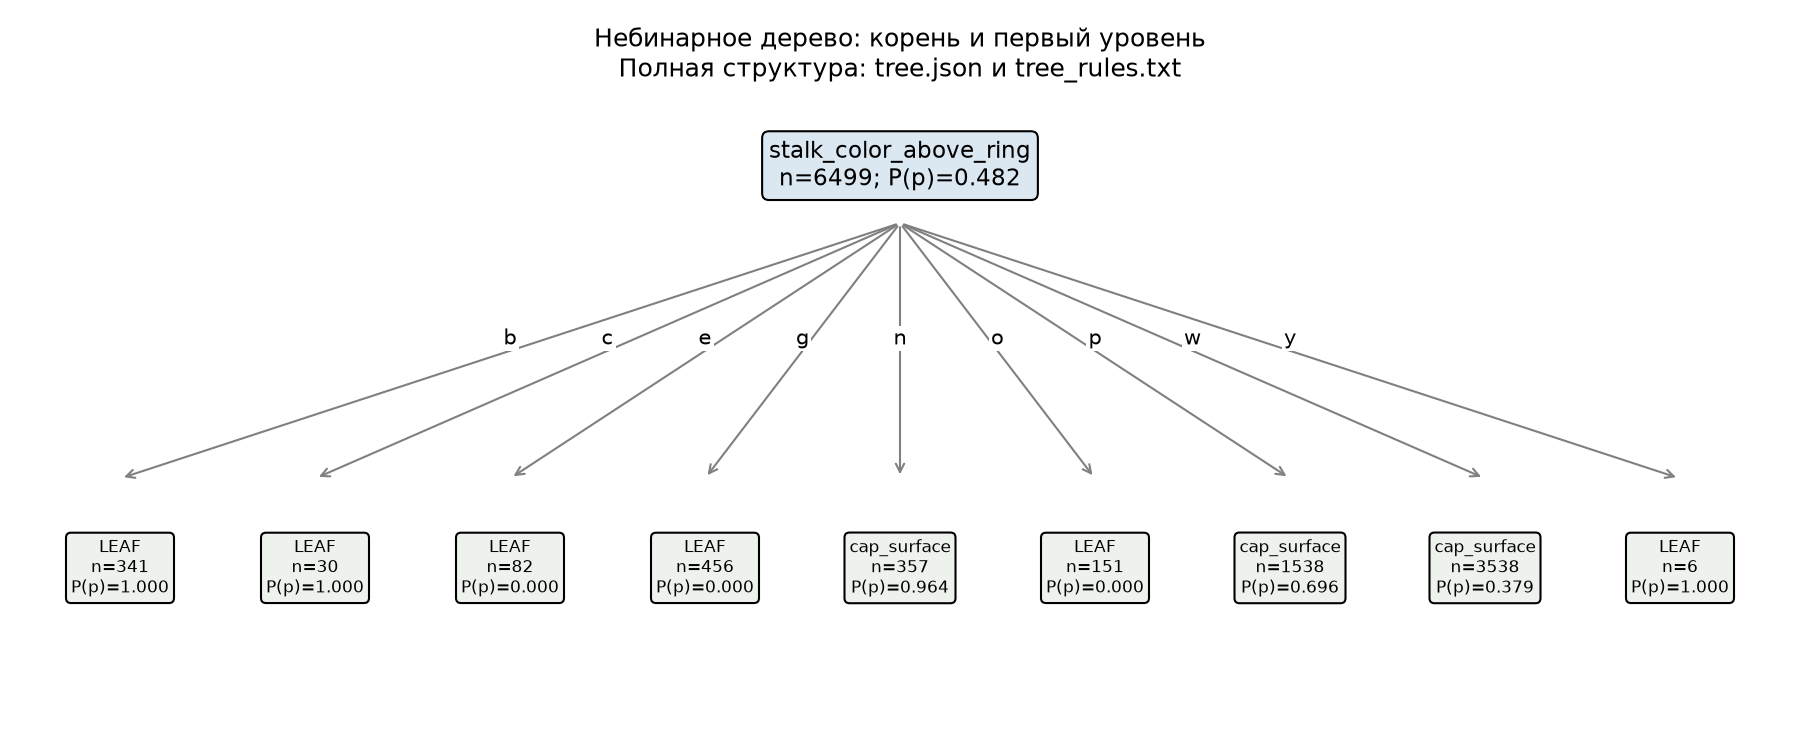

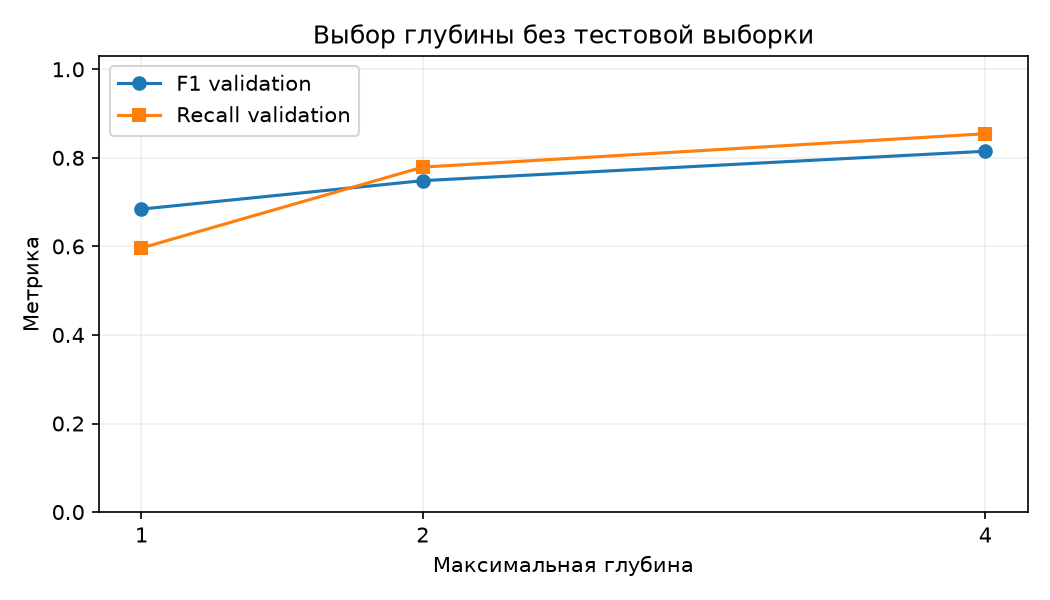

ROOT: n=6499, P(poisonous)=0.48207, split=stalk_color_above_ring, gain=0.255904
ROOT / stalk_color_above_ring=b: n=341, P(poisonous)=1.00000, LEAF
ROOT / stalk_color_above_ring=c: n=30, P(poisonous)=1.00000, LEAF
ROOT / stalk_color_above_ring=e: n=82, P(poisonous)=0.00000, LEAF
ROOT / stalk_color_above_ring=g: n=456, P(poisonous)=0.00000, LEAF
ROOT / stalk_color_above_ring=n: n=357, P(poisonous)=0.96359, split=cap_surface, gain=0.093716
ROOT / stalk_color_above_ring=n / cap_surface=f: n=174, P(poisonous)=1.00000, LEAF
ROOT / stalk_color_above_ring=n / cap_surface=s: n=5, P(poisonous)=0.00000, LEAF
ROOT / stalk_color_above_ring=n / cap_surface=y: n=178, P(poisonous)=0.95506, LEAF
ROOT / stalk_color_above_ring=o: n=151, P(poisonous)=0.00000, LEAF
ROOT / stalk_color_above_ring=p: n=1538, P(poisonous)=0.69636, split=cap_surface, gain=0.179983
ROOT / stalk_color_above_ring=p / cap_surface=f: n=422, P(poisonous)=0.43839, split=stalk_shape, gain=0.989019
ROOT / stalk_color_above_ring=p / cap_

In [3]:
for name in ['01_data.png', '02_confusion_roc_pr.png', '03_tree.png', '04_validation.png']:
    display(Image(filename=str(ROOT / 'results/figures' / name)))
print((ROOT / 'results/tree_rules.txt').read_text(encoding='utf-8'))

## Выводы
На test получены Accuracy ≈ 0.810, Precision ≈ 0.772, Recall для ядовитых ≈ 0.858 и ROC-AUC ≈ 0.897. Итоговое дерево имеет глубину 3, 30 узлов и 21 лист; в корне 9 ветвей при 2 классах. Полная структура сохранена в results/tree.json, все пути — в results/tree_rules.txt. При пороге 0.5 пропущено 111 ядовитых объектов. Результаты относятся к 1 разбиению и набору из 4 случайных признаков, 1 из которых постоянный.
